In [6]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt

In [ ]:
#1. load in the data and mac into FullMCRun object
#2. make the histograms (done)

## real data ##
#1. load in the data using my old code
#2. when do I change it to new 'format' with uproot?

#3. proceed outside of a root architechture

In [7]:
## ROOT stuff
import uproot
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

In [8]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4G4")+"/Batch/")
print(sys.path)

# for MC data getting
import helpers.FileGetters as FG

from G4_runClasses import *
from G4_macHelpers import *

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/']


In [9]:
pathToFiles = os.environ.get("CF4G4")+"/Batch/may5_2023-manualTesting_gammaHeights/"
print(pathToFiles)

## My Functions ##

# returns file f and ttree
def openMyROOT(sfile: str, treename = "simOutput"):
    if os.path.exists(sfile+".root") and os.path.exists(sfile+".mac"):
        f = TFile(sfile+".root", "READ")
        print("loaded in:", sfile+".root")
        return f, f.Get(treename)
    elif not os.path.exists(sfile+".root"):
        print("does not exist:", sfile+".root")
        return None, None
    elif not os.path.exists(sfile+".mac"):
        print("does not exist:", sfile+".mac")
        return None, None
    return None, None

# returns file f and ttree
# use upROOT instead
def openMyROOT_2(sfile: str, treeName = "simOutput"):
    if os.path.exists(sfile+".root") and os.path.exists(sfile+".mac"):
        f = uproot.open(sfile+".root")
        print("loaded in:", sfile+".root")
        return f, f[treeName]
    elif not os.path.exists(sfile+".root"):
        print("does not exist:", sfile+".root")
        return None, None
    elif not os.path.exists(sfile+".mac"):
        print("does not exist:", sfile+".mac")
        return None, None

/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/


In [10]:
# Opening files
fname = "Cs137_-0d5cm"
f1, tt1 = openMyROOT(pathToFiles+fname)
f1_b, tt1_b = openMyROOT_2(pathToFiles+fname)

fullF1 = FullMCRun(ttree = tt1, mac = pathToFiles+fname+".mac")

fullF1_b = FullMCRun(ttree = tt1_b, mac = pathToFiles+fname+".mac")

# print(fullF1.mPhysPars.ly)

fInDir = os.listdir(pathToFiles)
# fList = [f for f in fInDir if f.endswith('.root')]
# macList = [f for f in fInDir if f.endswith('.mac')]

loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_-0d5cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_-0d5cm.root


8063


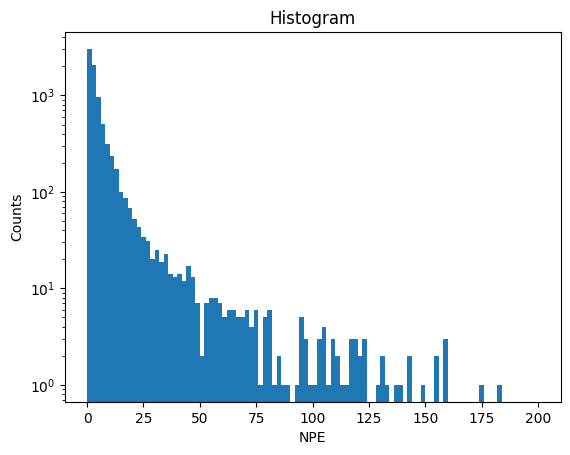

In [18]:
c = TCanvas()

fNPE = fullF1_b.mTtree["fNPE"].array()
fNPE = fNPE[fNPE > 0]
print(len(fNPE))

plt.hist(fNPE, bins=100, range=(0, 200))
plt.xlabel("NPE")
plt.ylabel("Counts")
plt.title("Histogram")
plt.yscale("log")
plt.show()

In [ ]:
# ## Building run objects, adding files and trees to run objects##
# if "runObjs" in vars():
#     del runObjs
# runObjs = []

# for f in fList:
#     ri = runInfo(f)
#     # ri.print()